# General Data Science Track — Session 04
## Explore a new 12×12 telemetry dataset
**MED-EL research preparation · Estimated core time: 60 minutes**

## Why this matters
Your first research question is **“What does one recording contain, and which variation is worth investigating?”** You will move between a matrix, a tidy contact-pair table, and patient/visit metadata, then produce interpretable figures. This is an exploratory research session: observations should generate questions, not diagnoses. You can start here without finishing the transaction notebook.

## Learning objectives
- Describe the patient → implant → visit → contact-pair hierarchy.
- Reconstruct a labeled 12×12 matrix without confusing IDs and array positions.
- Plot a heatmap and a field profile with meaningful scales and missingness.
- Separate diagonal/off-diagonal summaries and audit patient metadata joins.
- Write one quantitative observation and a follow-up question.

## R-to-Python bridge
| R idea | Python equivalent |
|---|---|
| `read_csv()` | `pd.read_csv()` |
| `pivot_wider()` | `.pivot(index=..., columns=..., values=...)` |
| `as.matrix(x)` | `x.to_numpy()` |
| `diag(M)` | `np.diag(M)` |
| `geom_tile()` | plotnine `geom_tile()` or Matplotlib `imshow()` |
| `left_join()` | `.merge(..., how="left", validate="many_to_one", indicator=True)` |

Pandas `.loc[3, 8]` uses labels; NumPy `[2, 7]` uses zero-based positions. A matrix is one representation of a visit, not 144 independent patients.

## Suggested pacing
Tasks 1–3: 19 min · Tasks 4–6: 23 min · Tasks 7–8: 10 min · Retrieval/reasoning/reflection: 8 min.

## Inputs and analysis contract
Start Jupyter from the repository root and select **Python (learning-python)** (`.venv`). All files already exist in `data/ci_telemetry/`; no downloads or prior notebook variables are needed. Read [the data dictionary](data/ci_telemetry/README.md) when a field is unfamiliar.

**All data are synthetic.** There are 96 patients with exactly one implant each, 360 observed visits, and 144 directed cell records per visit. Matrix rows stimulate; columns record. Contacts 1–12 have an index order but no claimed anatomical direction. These are teaching conventions, not a description of MED-EL's internal export. `voltage_mv / stim_current_ua` gives a synthetic V/I proxy in kΩ; it is not automatically the manufacturer's clinical impedance measurement. Preserve the original tables. Write short explanations in new markdown cells or print them. Exercise cells are intentionally empty.

Files for today: `patients.csv` (96×6), `visits.csv` (360×8), `matrix_cells.csv` (51,840×5). Use `CI001_M00` for your first heatmap. All 144 cell rows exist even if a value is unavailable. No anatomical labels, diagnostic cutoffs, or symmetry assumptions are supplied.

## Task 1 — A five-minute data handover (5 min)
Import pandas as `pd`, NumPy as `np`, and `matplotlib.pyplot as plt`; load the three files as `patients`, `visits`, and `cells`. Inspect `head()`, `shape`, and `dtypes`.

Before running: predict the number of rows for one selected visit and the number of independent patients represented by those rows. Write one sentence defining the row grain of each table. Confirm unique patient and visit keys and a unique three-column cell key.

Methods: `.nunique()`, `.isna()`, `.duplicated(subset=[...])`. For a composite key, check duplicates of the full column list, not each column separately.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load all 3 CSV files
patients = pd.read_csv('data/ci_telemetry/patients.csv')
visits = pd.read_csv('data/ci_telemetry/visits.csv')
cells = pd.read_csv('data/ci_telemetry/matrix_cells.csv')

In [6]:
# patients
print(patients.shape)
print(patients.dtypes)
print(patients.head())


(96, 6)
patient_id                  str
implant_id                  str
age_at_implant_years    float64
array_type                  str
site                        str
implant_side                str
dtype: object
  patient_id implant_id  age_at_implant_years array_type    site implant_side
0      CI001     IMP001                  29.0    array_A  site_2         left
1      CI002     IMP002                  68.0    array_B  site_2         left
2      CI003     IMP003                  61.0    array_B  site_3        right
3      CI004     IMP004                   NaN    array_A  site_1        right
4      CI005     IMP005                  49.0    array_B  site_2         left


In [7]:
# visits
print(visits.shape)
print(visits.dtypes)
print(visits.head())

(360, 8)
visit_id                  str
patient_id                str
implant_id                str
visit_month             int64
days_since_implant      int64
visit_date                str
protocol                  str
stim_current_ua       float64
dtype: object
    visit_id patient_id implant_id  visit_month  days_since_implant  \
0  CI001_M00      CI001     IMP001            0                   0   
1  CI001_M01      CI001     IMP001            1                  26   
2  CI001_M03      CI001     IMP001            3                  92   
3  CI001_M06      CI001     IMP001            6                 179   
4  CI002_M00      CI002     IMP002            0                   0   

   visit_date protocol  stim_current_ua  
0  2024-02-05       v1            100.0  
1  2024-03-02       v2            100.0  
2  2024-05-07       v2            150.0  
3  2024-08-02       v2            100.0  
4  2024-02-13       v1            150.0  


In [8]:
#cells
print(cells.shape)
print(cells.dtypes)
print(cells.head())

(51840, 5)
visit_id              str
stim_contact        int64
record_contact      int64
voltage_mv        float64
qc_status             str
dtype: object
    visit_id  stim_contact  record_contact  voltage_mv qc_status
0  CI001_M00             1               1    362.8632        ok
1  CI001_M00             1               2    120.9755        ok
2  CI001_M00             1               3     73.2011        ok
3  CI001_M00             1               4     51.2933        ok
4  CI001_M00             1               5     34.8980        ok


## Task 2 — Join measurement settings and mask unusable entries (7 min)
Create `telemetry` by left-merging `cells` with `visits` on `visit_id`, using `validate="many_to_one"` and `indicator=True`. Inspect `_merge` and assert every row matched. Keep all 51,840 rows.

Count each `qc_status` and compare missing voltages with non-`ok` flags. A saturated measurement is finite here: missing-value checks alone are insufficient. Create `z_kohm` as voltage divided by current, retaining values only where status is `ok` and voltage is finite. Verify all currents are positive. Do not fill unknowns with zero.

Methods: `.value_counts(dropna=False)`, `np.isfinite(...)`, `.where(mask)`.

Unrelated masking example:
```python
lab["usable_temperature"] = lab["temperature"].where(lab["flag"].eq("valid"))
```
Explain the units of mV / µA and why equal voltages measured at different currents need not imply equal V/I values.

In [15]:
telemetry = pd.merge(cells, visits, how='left', on='visit_id', validate='many_to_one', indicator=True)
telemetry.head()

,visit_id,stim_contact,record_contact,voltage_mv,qc_status,patient_id,implant_id,visit_month,days_since_implant,visit_date,protocol,stim_current_ua,_merge
0,CI001_M00,1,1,362.8632,ok,CI001,IMP001,0,0,2024-02-05,v1,100.0,both
1,CI001_M00,1,2,120.9755,ok,CI001,IMP001,0,0,2024-02-05,v1,100.0,both
2,CI001_M00,1,3,73.2011,ok,CI001,IMP001,0,0,2024-02-05,v1,100.0,both
3,CI001_M00,1,4,51.2933,ok,CI001,IMP001,0,0,2024-02-05,v1,100.0,both
4,CI001_M00,1,5,34.8980,ok,CI001,IMP001,0,0,2024-02-05,v1,100.0,both


In [18]:
telemetry["_merge"].value_counts()

_merge
both          51840
left_only         0
right_only        0
Name: count, dtype: int64

In [20]:
#Count qc_status
telemetry["qc_status"].value_counts()

qc_status
ok              51040
not_recorded      752
saturated          48
Name: count, dtype: int64

In [25]:
print(telemetry.loc[telemetry['qc_status'] != 'ok', "voltage_mv"].value_counts())
print(telemetry.loc[telemetry['qc_status'] != 'ok', "voltage_mv"].isna().sum())

voltage_mv
2000.0    48
Name: count, dtype: int64
752


Learning: The voltage is either 2000 or missing on non-ok quality checks

In [32]:
assert (telemetry["stim_current_ua"] > 0).all()

usable = (
    telemetry["qc_status"].eq("ok")
    & np.isfinite(telemetry["voltage_mv"])
)

telemetry["z_kohm"] = (
    telemetry["voltage_mv"] / telemetry["stim_current_ua"]
).where(usable)

## Task 3 — Reconstruct one matrix (7 min)
Select `CI001_M00` into `one_visit`. Use `.pivot()` to create `matrix` with stimulating contacts on rows, recording contacts on columns, and `z_kohm` as values. Explicitly order both axes 1–12, then create a NumPy array named `M`.

Acceptance: `one_visit` has 144 rows; `matrix.shape` and `M.shape` are `(12, 12)`; row/column labels are 1–12. Identify the same cell using `matrix.loc[3, 8]` and `M[2, 7]` and check equality. Explain why `.pivot()` failing on duplicate pairs is a useful warning.

Unrelated reshape example:
```python
plate = readings.pivot(index="row_label", columns="column_label", values="signal")
```
Hint: `.reindex(index=range(1, 13), columns=range(1, 13))` establishes contact order.

In [40]:
one_visit = telemetry.loc[telemetry['visit_id'] == 'CI001_M00']
matrix =one_visit.pivot(index='stim_contact', columns = 'record_contact', values='z_kohm').reindex(index = range(1,13), columns = range(1,13))

M = matrix.to_numpy()

In [42]:
matrix

record_contact,1,2,3,4,5,6,7,8,9,10,11,12
stim_contact,,,,,,,,,,,,
1,3.628632,1.209755,0.732011,0.512933,0.348980,0.216316,0.206040,0.209790,0.141329,0.134824,0.148250,0.142393
2,1.194302,3.687641,1.183946,0.772459,0.537506,0.349037,0.266908,0.217249,0.211685,0.211527,0.079525,0.123877
3,0.797349,1.213336,NaN,1.116640,0.834258,0.537135,0.382170,0.260551,0.206879,0.198536,0.144676,0.139405
4,0.618977,0.879991,1.184724,3.964637,1.218074,0.790166,0.597321,0.414274,0.293403,0.241986,0.251845,0.223994
5,0.467285,0.611917,0.871436,1.167123,NaN,1.179816,0.812755,0.529142,0.345221,0.225438,0.190671,0.167506
6,0.367731,0.532659,0.645020,0.800095,1.208891,3.706735,1.170769,0.808254,0.579981,0.388982,0.335227,0.189811
7,0.326001,0.468911,0.472664,0.656472,0.836971,1.217049,3.679233,1.174757,0.774486,0.573370,0.371052,0.321288
8,0.333544,0.338608,0.367974,0.480745,0.595506,0.866512,NaN,3.675210,1.111043,NaN,0.606045,0.432188
9,0.254118,0.242972,0.222021,0.358970,0.549571,0.621531,0.814183,1.212999,3.680500,1.170315,0.805249,0.555296


In [43]:
print(one_visit.shape[0])  # 144
print(matrix.shape)       # (12, 12)
print(M.shape)            # (12, 12)

print(matrix.loc[3, 8], M[2, 7])


144
(12, 12)
(12, 12)
0.260551 0.260551


## Task 4 — Make the first scientific figure (8 min)
Plot `M` as a heatmap with a colorbar labeled **synthetic V/I proxy (kΩ)**. Put recording contact on x, stimulating contact on y, show labels 1–12, and title it with patient and visit. Give missing values a visibly separate color. Keep the same row direction in later plots.

Methods: `plt.subplots()`, `ax.imshow(..., origin="upper", vmin=..., vmax=...)`, `fig.colorbar(...)`, `ax.set(...)`.

Unrelated plotting example:
```python
palette = plt.get_cmap("viridis").copy()
palette.set_bad("lightgray")
fig, ax = plt.subplots(figsize=(5, 4))
img = ax.imshow(sensor_grid, cmap=palette, origin="upper")
fig.colorbar(img, ax=ax, label="Temperature (°C)")
```
Hint: image positions are 0–11; labels are 1–12. Describe the diagonal and one off-diagonal pattern. If the diagonal dominates the color scale, explain what a second off-diagonal-only view could reveal.

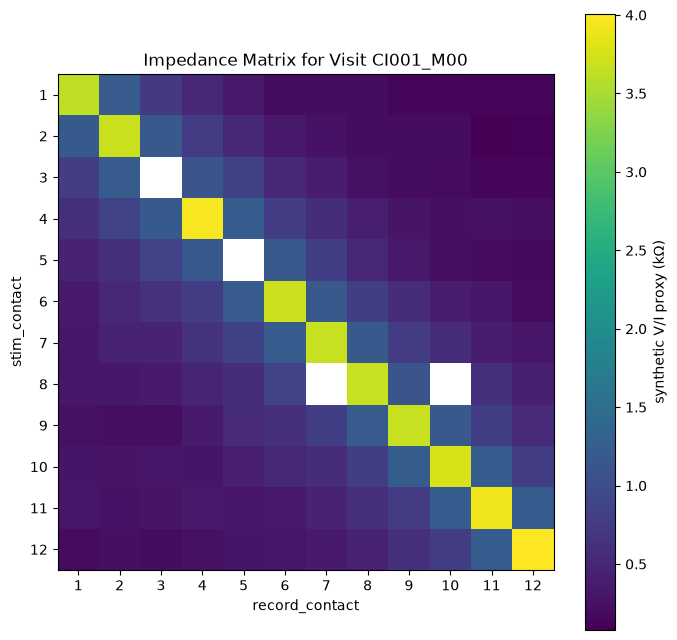

In [48]:
plt.subplots(figsize=(8, 8))

plt.imshow(M, cmap='viridis', interpolation='none')

# labelling
plt.colorbar(label='synthetic V/I proxy (kΩ)')
plt.xlabel('record_contact')
plt.xticks(ticks=range(12), labels=range(1, 13))
plt.ylabel('stim_contact')
plt.yticks(ticks=range(12), labels=range(1, 13))

plt.title('Impedance Matrix for Visit CI001_M00')
plt.show()

## Task 5 — Field profiles and directionality (8 min)
For `CI001_M00`, select stimulating contacts 2, 6, and 10. With plotnine, draw `z_kohm` against recording contact, grouped and colored by stimulating contact. Treat the color as categorical; sort contacts and preserve missing gaps. Mark or explain the diagonal peaks.

Useful imports: `ggplot`, `aes`, `geom_line`, `geom_point`, `labs`, `theme_minimal`. A profile compares recording contacts **within a fixed stimulation row**.

Unrelated plotnine pattern:
```python
(ggplot(weather, aes("hour", "temperature", color="station", group="station"))
 + geom_line() + geom_point() + theme_minimal())
```
Then compare `M` with `M.T` using the mean absolute difference where both paired entries are finite. Is exact symmetry supported? Do not replace the matrix with a symmetric average. Hint: transpose is `.T`, and `np.nanmean(np.abs(...))` ignores missing paired differences.

In [50]:
from plotnine import *

In [60]:
plot_selection = one_visit.loc[(one_visit['stim_contact'] == 2) | 
                               (one_visit['stim_contact'] == 6) | 
                               (one_visit['stim_contact'] == 10),
                               ['stim_contact', 'record_contact', 'z_kohm']]

plot_selection['stim_contact'] = plot_selection['stim_contact'].astype(str)

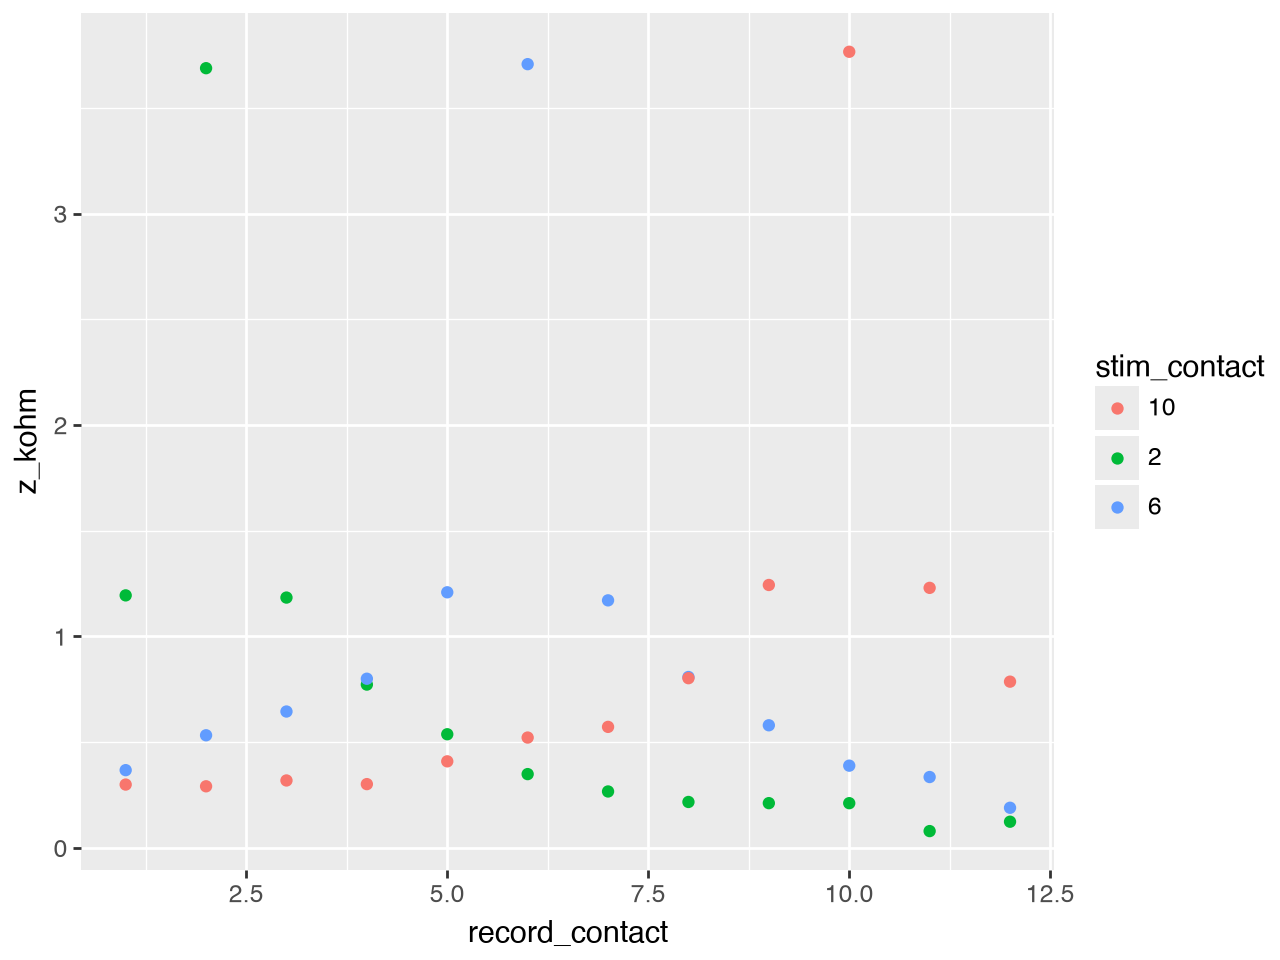

In [61]:
(ggplot(plot_selection, aes(x='record_contact', y='z_kohm', color='stim_contact')) +
    geom_point())

## Task 6 — Useful summaries with explicit denominators (7 min)
Add `contact_distance = abs(stim_contact - record_contact)` to `telemetry`. For **each visit**, calculate the mean valid diagonal `z_kohm` and the number of contributing diagonal cells into `diag_summary`.

Acceptance: 360 rows; unique `visit_id`; `n_diag_valid` between 10 and 12. Name the columns `diag_mean_kohm` and `n_diag_valid`. Separately compare the mean of near entries (distance 1) with far entries (distance ≥6) for `CI001_M00`. These are index distances, not physical distances.

Hint: filter the diagonal **before** `.groupby("visit_id").agg(...)`. Named aggregation gives readable output columns. `count` counts nonmissing values; `size` counts cell rows. Explain why averaging all 144 entries answers a different question.

In [71]:
telemetry["contact_distance"] = abs(telemetry["stim_contact"] - telemetry["record_contact"])
telemetry.head()

diagonal = telemetry.loc[telemetry["contact_distance"] == 0]


diagonal_summary = diagonal.groupby("visit_id").agg(
    diagonal_mean_kohm = ("z_kohm", "mean"),
    n_diagonal_valid = ("z_kohm", "count")     
).reset_index()
diagonal_summary

,visit_id,diagonal_mean_kohm,n_diagonal_valid
0,CI001_M00,3.770924,10
1,CI001_M01,4.027151,12
2,CI001_M03,4.322224,12
3,CI001_M06,4.391055,12
4,CI002_M00,6.807697,12
...,...,...,...
355,CI095_M06,5.605965,12
356,CI096_M00,5.971229,12
357,CI096_M01,6.623744,12
358,CI096_M03,6.170860,11


In [76]:
assert len(diagonal_summary) == 360
assert diagonal_summary["visit_id"].is_unique
assert diagonal_summary["n_diagonal_valid"].between(10, 12).all()

## Task 7 — Bring in patient context (6 min)
Join `diag_summary` to `visits` using `validate="one_to_one"`, then to `patients` on `patient_id` using `validate="many_to_one"`. For the second join use patient fields `patient_id`, `age_at_implant_years`, `array_type`, and `site` to avoid duplicate implant columns. Inspect unmatched keys at both joins; retain 360 rows.

Restrict to `visit_month == 0` before plotting a boxplot plus jittered points of `diag_mean_kohm` by `array_type`. This gives one observation per patient. Use plotnine `geom_boxplot(outlier_shape="")` and `geom_jitter(width=0.1, height=0, random_state=42)` to avoid duplicating outlier symbols.

Report baseline sample counts and group medians. What patient characteristic or measurement setting could explain part of a group difference?

In [80]:
patients

,patient_id,implant_id,age_at_implant_years,array_type,site,implant_side
0,CI001,IMP001,29.0,array_A,site_2,left
1,CI002,IMP002,68.0,array_B,site_2,left
2,CI003,IMP003,61.0,array_B,site_3,right
3,CI004,IMP004,NaN,array_A,site_1,right
4,CI005,IMP005,49.0,array_B,site_2,left
...,...,...,...,...,...,...
91,CI092,IMP092,70.0,array_A,site_2,right
92,CI093,IMP093,72.0,array_A,site_2,left
93,CI094,IMP094,46.0,array_A,site_3,right
94,CI095,IMP095,75.0,array_B,site_1,right


In [85]:
interm = pd.merge(diagonal_summary, visits, on="visit_id", validate="many_to_one")
patient_context = pd.merge(
    interm,
    patients[["patient_id", "age_at_implant_years", "array_type", "site"]],
    on="patient_id",
    how="left",
    validate="many_to_one"
)
patient_context = patient_context.loc[patient_context["visit_month"] == 0]

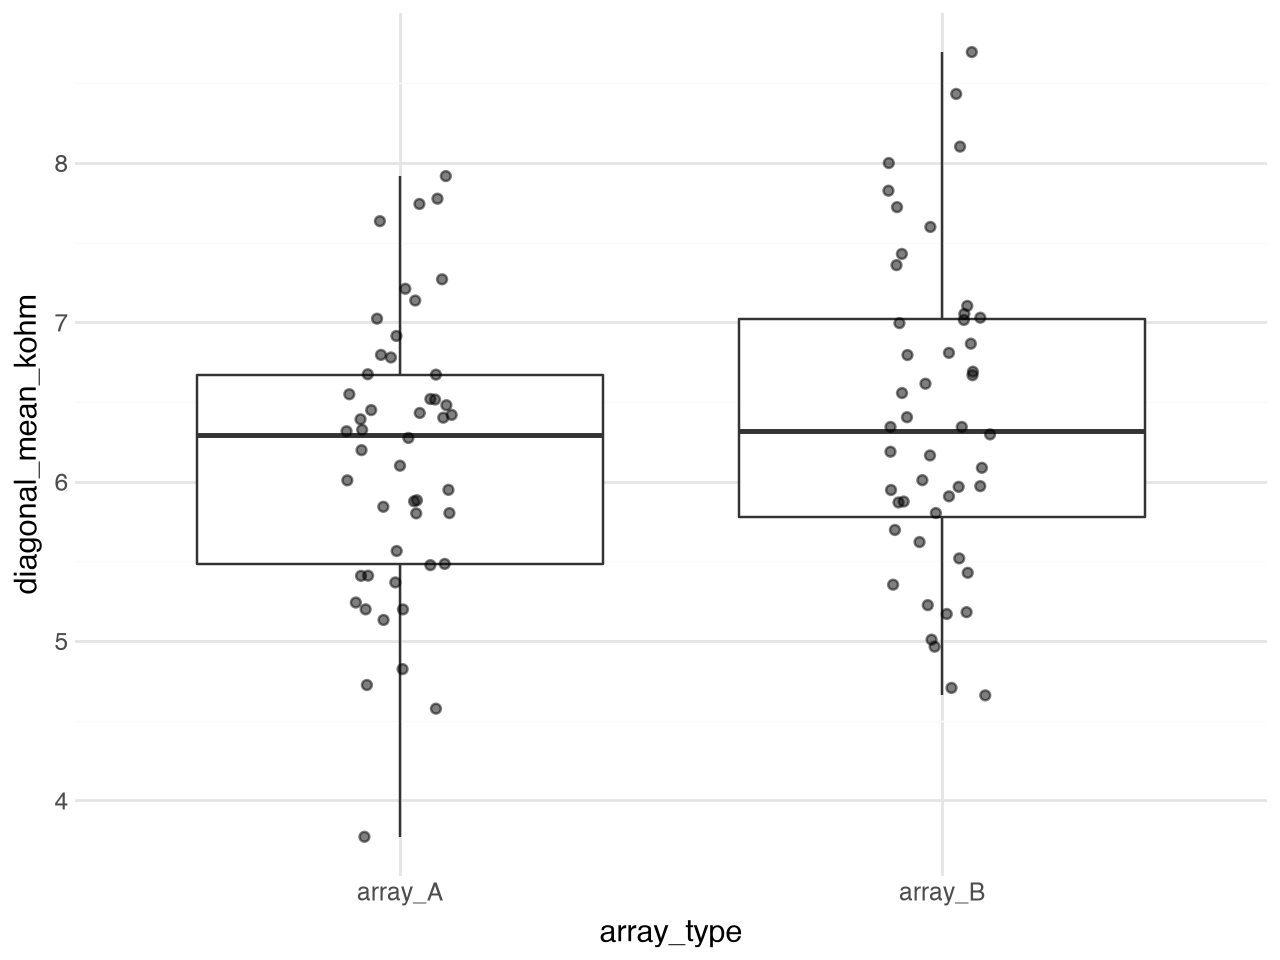

In [92]:
(
    ggplot(patient_context, aes(x = "array_type", y = "diagonal_mean_kohm")) + 
    geom_boxplot(outlier_shape = "") + 
    geom_jitter(width = 0.1, height = 0, alpha = 0.5) + 
    theme_minimal()
)

## Task 8 — A research note, not a diagnosis (4 min)
Write four short sentences: (1) a numerical observation, (2) what the heatmap/profile adds beyond a mean, (3) one alternative measurement-related explanation, and (4) the next plot or comparison you would request.

Include two questions for the real data owner: one about matrix meaning/units and one about repeated visits, implants, or QC. Distinguish something you observed from something you merely hypothesize.

## Retrieval practice
Without copying Task 3, reconstruct `CI007_M03` and plot it beside `CI007_M00` using the **same** color limits and contact order. Use limits covering both matrices' finite values. State one localized difference that a single whole-matrix mean could hide. No clinical label is justified by this comparison.

## Professional reasoning
1. Why do 51,840 cell rows not provide 51,840 independent patient observations?
2. What could go wrong if you retained only one triangle without checking measurement direction?
3. Why does masking saturated values differ from deleting high but valid observations?

## Self-check and reflection
Record confidence **1–5**, the hardest point, one operation you can now explain, what needs repetition, and whether the workload was too light / about right / too heavy.

Finish line: restart the kernel, run your cells in order, and write a short research conclusion with its limitations. Ask for review of your attempt.

## Optional extension — outside the core hour
**20–30 minutes:** Build an off-diagonal-only heatmap and profiles for the unusual visit. Try row normalization, documenting the denominator, and compare with the unnormalized view. Explain which absolute-amplitude information normalization removes. Propose a check that separates a local artifact from a persistent change; do not invent a diagnostic threshold.